## Setup: Dependencies & Data

**Note on data source:** The public data is normally hosted on NERSC, but direct downloads from there were intermittently blocked/unreliable in Colab. To avoid that flakiness, I mirrored the dataset to a GitHub Release (`mqurban/pz-challenge-taskset1`) and download from there instead — same data, just a more reliable host for this environment.

- **Cell 1** installs the required packages (`qp-prob`, `tables_io`, `h5py`, `lightgbm`).
- **Cell 2** downloads and extracts the public dataset from the GitHub Release mirror.

In [ ]:
# Cell 1: Install dependencies
!pip install qp-prob tables_io h5py lightgbm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.9/112.9 kB 4.8 MB/s eta 0:00:00


In [ ]:
# Cell 2: Download public data from GitHub Release
%cd /content
!wget -q https://github.com/mqurban/pz-challenge-taskset1/releases/download/v1.0-data/public.tgz
!tar -xzf public.tgz
!ls public/

/content
pz_challenge_taskset_1_cardinal_test_10yr.hdf5
pz_challenge_taskset_1_cardinal_test_1yr.hdf5
pz_challenge_taskset_1_cardinal_training_10yr.hdf5
pz_challenge_taskset_1_cardinal_training_1yr.hdf5
pz_challenge_taskset_1_flagship_test_10yr.hdf5
pz_challenge_taskset_1_flagship_test_1yr.hdf5
pz_challenge_taskset_1_flagship_training_10yr.hdf5
pz_challenge_taskset_1_flagship_training_1yr.hdf5
pz_challenge_taskset_2_cardinal_test_10yr.hdf5
pz_challenge_taskset_2_cardinal_test_1yr.hdf5
pz_challenge_taskset_2_cardinal_training_10yr.hdf5
pz_challenge_taskset_2_cardinal_training_1yr.hdf5
pz_challenge_taskset_2_flagship_test_10yr.hdf5
pz_challenge_taskset_2_flagship_test_1yr.hdf5
pz_challenge_taskset_2_flagship_training_10yr.hdf5
pz_challenge_taskset_2_flagship_training_1yr.hdf5
pz_challenge_taskset_3_cardinal_test_10yr.hdf5
pz_challenge_taskset_3_cardinal_test_1yr.hdf5
pz_challenge_taskset_3_cardinal_training_10yr.hdf5
pz_challenge_taskset_3_cardinal_training_1yr.hdf5
pz_challenge_taskset_

## Task Set 1: Pipeline Overview

- **Model:** LightGBM regressor per (simulation, scenario) pair — 4 runs total (Cardinal/Flagship × 1yr/10yr)
- **Target:** redshift, log1p-transformed for training; predictions reversed with expm1
- **Features:** LSST ugrizy mags + SNR, Roman YJH mags + SNR, all pairwise LSST colors, all pairwise Roman colors, and **LSST–Roman cross-survey colors** (main driver for breaking optical color degeneracy)
- **Training:** 8000 max trees, learning rate 0.005, early stopping patience 400 rounds (custom sigma_MAD eval metric)
- **Point-estimate metrics:** bias (median Δz/(1+z)), sigma_MAD, sigma_RMSE (full validation set incl. outliers), outlier rate (|Δz/(1+z)| > 0.06)
- **p(z) construction:** 3-component Gaussian mixture per object —
  - Component 1: tight prediction around point estimate
  - Component 2: 200-nearest-neighbor redshift distribution
  - Component 3: broadened fallback (2.5× neighbor spread)
  - Component weights and widths scale adaptively with i-band faintness (fainter → wider, more neighbor-weighted)
- **p(z) metrics:** PIT (via CDF interpolation on a 400-pt redshift grid, 0–4), PIT RMSE (vs. ideal uniform), CDE Loss
- **Outputs per scenario:** trained model (`.pkl`), qp ensemble p(z) (`.hdf5`), PIT histogram (`.png`)

In [ ]:
# Cell 3
# ============================================
# TASK SET 1: PZ ESTIMATION
# ============================================

import numpy as np
import pandas as pd
import h5py
import qp
import pickle
import os
import time
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from collections import OrderedDict

# ML libraries
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')
warnings.filterwarnings('ignore', message='X has feature names')

# Paths
BASE_PATH = Path('/content')
PUBLIC_PATH = BASE_PATH / 'public'
OUTPUT_PATH = BASE_PATH / 'outputs'
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("TASK SET 1: PHOTOMETRIC REDSHIFT ESTIMATION")
print("=" * 60)

def load_hdf5_to_df(filename):
    """Load DESC HDF5 file into pandas DataFrame.

    The files have individual datasets at top level for each column.
    """
    with h5py.File(filename, 'r') as f:
        # Get all dataset names
        columns = list(f.keys())

        # Build dictionary of column data
        data = {}
        for col in columns:
            data[col] = f[col][:]

        # Convert to DataFrame
        return pd.DataFrame(data)

def preprocess_features(df):
    """Create ML features from raw photometry."""
    df = df.copy()

    # LSST bands
    lsst_bands = ['u', 'g', 'r', 'i', 'z', 'y']
    roman_bands = ['Y', 'J', 'H']

    # Feature list
    feature_cols = []

    # Process LSST bands
    for band in lsst_bands:
        mag_col = f'mag_{band}_lsst'
        err_col = f'mag_{band}_lsst_err'

        # Convert errors to SNR (Signal-to-Noise Ratio) where possible
        if err_col in df.columns:
            snr_col = f'snr_{band}_lsst'
            # Prevent division by zero, though typically errors > 0
            df[snr_col] = np.where(df[err_col] > 0, 1.0857 / df[err_col], 0.0)
            feature_cols.extend([mag_col, snr_col])
        else:
            if mag_col in df.columns:
                feature_cols.extend([mag_col])

    # Process Roman bands
    for band in roman_bands:
        mag_col = f'mag_{band}_roman'
        err_col = f'mag_{band}_roman_err'
        if mag_col in df.columns:
            if err_col in df.columns:
                snr_col = f'snr_{band}_roman'
                df[snr_col] = np.where(df[err_col] > 0, 1.0857 / df[err_col], 0.0)
                feature_cols.extend([mag_col, snr_col])
            else:
                feature_cols.extend([mag_col])

    # Get available bands for colors
    avail_lsst = [b for b in lsst_bands if f'mag_{b}_lsst' in df.columns]
    avail_roman = [b for b in roman_bands if f'mag_{b}_roman' in df.columns]

    colors = []

    # All pairwise LSST colors
    for i in range(len(avail_lsst)):
        for j in range(i+1, len(avail_lsst)):
            c1, c2 = avail_lsst[i], avail_lsst[j]
            color_name = f'color_{c1}_{c2}_lsst'
            df[color_name] = df[f'mag_{c1}_lsst'] - df[f'mag_{c2}_lsst']
            colors.append(color_name)

    # All pairwise Roman colors
    for i in range(len(avail_roman)):
        for j in range(i+1, len(avail_roman)):
            c1, c2 = avail_roman[i], avail_roman[j]
            color_name = f'color_{c1}_{c2}_roman'
            df[color_name] = df[f'mag_{c1}_roman'] - df[f'mag_{c2}_roman']
            colors.append(color_name)

    # Cross-survey colors (LSST - Roman)
    # Long-baseline colors (optical to infrared) are excellent at breaking redshift degeneracies
    for b_lsst in avail_lsst:
        for b_roman in avail_roman:
            color_name = f'color_{b_lsst}_lsst_{b_roman}_roman'
            df[color_name] = df[f'mag_{b_lsst}_lsst'] - df[f'mag_{b_roman}_roman']
            colors.append(color_name)

    feature_cols.extend(colors)

    # We DO NOT fill NaNs with 99.0 anymore. We let LightGBM handle them directly!

    return df, feature_cols

import lightgbm as lgb

def sigma_mad_eval(y_true, y_pred):
    """Custom LightGBM metric: SigmaMAD on (z_pred - z) / (1 + z)"""
    # y_true and y_pred are log1p transformed
    z_true = np.expm1(y_true)
    z_pred = np.expm1(y_pred)
    delta = (z_pred - z_true) / (1.0 + z_true)
    sigma_mad = 1.4862 * np.median(np.abs(delta - np.median(delta)))
    return 'sigma_mad', sigma_mad, False  # False means lower is better

def train_lightgbm_model(X_train, y_train, X_val, y_val, feature_cols):
    """Train LightGBM for redshift estimation."""
    model = lgb.LGBMRegressor(
        n_estimators=8000,          # Massive number of trees
        max_depth=12,
        learning_rate=0.005,        # Ultra-slow learning to squeeze out the last bit of accuracy
        num_leaves=256,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=3,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric=sigma_mad_eval,
        callbacks=[lgb.early_stopping(400, verbose=True)] # massive patience for slow learning
    )

    return model

def build_pz_distribution(model, X_train, y_train, X_test, object_ids,
                          feature_cols, n_neighbors=200, n_components=3):
    """Build p(z) as Gaussian mixture with ADAPTIVE uncertainty."""
    print("  → Predicting point estimates...")
    # Reverse the log1p transformation from training
    z_pred = np.expm1(model.predict(X_test))

    # Reverse log1p for the training targets used in nearest neighbors
    y_train_raw = np.expm1(y_train)

    print(f"  → Finding {n_neighbors} nearest neighbors...")
    # sklearn NearestNeighbors cannot handle NaNs, so we impute them with 99.0
    # strictly for the distance calculations.
    X_train_nn = np.nan_to_num(X_train, nan=99.0)
    X_test_nn = np.nan_to_num(X_test, nan=99.0)

    nn = NearestNeighbors(n_neighbors=n_neighbors, n_jobs=-1, algorithm='kd_tree')
    nn.fit(X_train_nn)
    distances, indices = nn.kneighbors(X_test_nn)

    print("  → Building Gaussian mixtures with ADAPTIVE uncertainty...")

    # Extract i-band magnitude for adaptive uncertainty
    # Find mag_i_lsst index in feature_cols
    try:
        i_mag_idx = feature_cols.index('mag_i_lsst')
        i_mag = X_test[:, i_mag_idx]
    except ValueError:
        i_mag = np.full(len(X_test), 22.0)  # Default if not found

    n_test = len(X_test)
    means_arr = np.zeros((n_test, n_components))
    stds_arr = np.zeros((n_test, n_components))
    weights_arr = np.zeros((n_test, n_components))

    for i in tqdm(range(n_test), desc="  Building p(z)", leave=False):
        neighbor_z = y_train_raw[indices[i]]

        # ADAPTIVE: fainter galaxies = larger uncertainty
        # i=22 is bright (good data), i=23 is faint (noisy)
        faintness = max(0, i_mag[i] - 21.5)  # 0 for bright, up to ~1.5 for faint

        # Base uncertainty scales with faintness
        base_std = 0.03 + 0.04 * faintness  # 0.03 for bright, 0.09 for faint

        # Neighbor spread adds to uncertainty
        neighbor_std = np.std(neighbor_z) + 0.02 + 0.03 * faintness

        # Component 1: Tight prediction (high confidence, lower weight for faint)
        pred_weight = max(0.2, 0.6 - 0.15 * faintness)

        # Component 2: Neighbor distribution (broader, higher weight for faint)
        neighbor_weight = min(0.5, 0.3 + 0.1 * faintness)

        # Component 3: Conservative fallback
        fallback_weight = 1.0 - pred_weight - neighbor_weight

        means_arr[i, 0] = z_pred[i]
        means_arr[i, 1] = np.median(neighbor_z)
        means_arr[i, 2] = z_pred[i]

        stds_arr[i, 0] = base_std
        stds_arr[i, 1] = neighbor_std
        stds_arr[i, 2] = neighbor_std * 2.5  # Even broader fallback

        weights_arr[i, 0] = pred_weight
        weights_arr[i, 1] = neighbor_weight
        weights_arr[i, 2] = fallback_weight

    # Normalize weights
    weights_arr = weights_arr / weights_arr.sum(axis=1, keepdims=True)

    print("  → Creating qp ensemble...")
    ens = qp.mixmod.create_ensemble(
        means=means_arr,
        stds=stds_arr,
        weights=weights_arr
    )

    # REQUIRED ancillary data
    ens.set_ancil({
        'zmode': z_pred,
        'object_id': object_ids
    })

    return ens

def process_scenario(sim, scenario):
    """Process one simulation + scenario combination."""
    print(f"\n{'='*60}")
    print(f"Processing: {sim.upper()} / {scenario}")
    print(f"{'='*60}")

    train_file = PUBLIC_PATH / f'pz_challenge_taskset_1_{sim}_training_{scenario}.hdf5'
    test_file = PUBLIC_PATH / f'pz_challenge_taskset_1_{sim}_test_{scenario}.hdf5'

    if not train_file.exists():
        print(f"⚠ WARNING: {train_file} not found, skipping...")
        return None

    # Load data
    print("Loading training data...")
    train_df = load_hdf5_to_df(train_file)
    print(f"  Training samples: {len(train_df):,}")
    print(f"  Columns: {list(train_df.columns)}")

    print("Loading test data...")
    test_df = load_hdf5_to_df(test_file)
    print(f"  Test samples: {len(test_df):,}")

    # Preprocess
    print("Preprocessing features...")
    train_df, feature_cols = preprocess_features(train_df)
    test_df, _ = preprocess_features(test_df)

    print(f"  Features ({len(feature_cols)}): {feature_cols[:10]}...")
    if len(feature_cols) > 10:
        print(f"  ... and {len(feature_cols)-10} more")

    # Check columns exist
    if 'redshift' not in train_df.columns:
        raise KeyError(f"No 'redshift' column! Available: {list(train_df.columns)}")
    if 'object_id' not in test_df.columns:
        raise KeyError(f"No 'object_id' column! Available: {list(test_df.columns)}")

    # Split for validation
    X = train_df[feature_cols].values
    # Transform target variable using log1p
    y = np.log1p(train_df['redshift'].values)

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.15, random_state=42
    )

    # Train
    print("Training LightGBM model...")
    t0_train = time.time()
    model = train_lightgbm_model(X_train, y_train, X_val, y_val, feature_cols)
    t1_train = time.time()
    print(f"  ⏱️ Training Time: {t1_train - t0_train:.2f} seconds")

    # Validate
    print("Validating...")
    # Reverse log1p transformations for validation metrics
    val_pred = np.expm1(model.predict(pd.DataFrame(X_val, columns=feature_cols)))
    y_val_raw = np.expm1(y_val)
    delta = (val_pred - y_val_raw) / (1 + y_val_raw)

    bias = np.median(delta)
    sigma_mad = 1.4862 * np.median(np.abs(delta - np.median(delta)))
    outlier_rate = np.mean(np.abs(delta) > 0.06)

    # Calculate Sigma RMSE (over the full validation set, including outliers)
    sigma_rmse = np.sqrt(np.mean(delta**2))

    print(f"\n  📊 Validation Metrics:")
    print(f"     Bias:      {bias:.5f}")
    print(f"     Sigma MAD: {sigma_mad:.5f}")
    print(f"     Sigma RMSE:{sigma_rmse:.5f}")
    print(f"     Outlier:   {outlier_rate:.4f} ({outlier_rate*100:.2f}%)")

    # Evaluate p(z) on Validation Set for PIT & CDE Loss
    print("\n  → Generating p(z) on Validation Set for PIT evaluation...")
    try:
        i_mag_idx = feature_cols.index('mag_i_lsst')
        i_mag_val = X_val[:, i_mag_idx]
    except ValueError:
        i_mag_val = np.full(len(X_val), 22.0)

    t0_inf = time.time()
    ens_val = build_pz_distribution(model, X_train, y_train, X_val, np.arange(len(X_val)), feature_cols)
    t1_inf = time.time()
    print(f"  ⏱️ Inference Time (15k samples): {t1_inf - t0_inf:.2f} seconds")

    print("  → Computing PIT and CDE Loss...")
    z_grid = np.linspace(0, 4.0, 400)
    pdf_grid = ens_val.pdf(z_grid)
    cdf_grid = ens_val.cdf(z_grid)

    pit_vals = np.array([np.interp(y_val_raw[i], z_grid, cdf_grid[i]) for i in range(len(y_val_raw))])
    p_true_vals = np.array([np.interp(y_val_raw[i], z_grid, pdf_grid[i]) for i in range(len(y_val_raw))])
    integral_vals = np.trapezoid(pdf_grid**2, x=z_grid, axis=1)
    cde_losses = integral_vals - 2 * p_true_vals

    mean_cde_loss = np.mean(cde_losses)
    sorted_pit = np.sort(pit_vals)
    ideal_uniform = np.linspace(0, 1, len(sorted_pit))
    pit_rmse = np.sqrt(np.mean((sorted_pit - ideal_uniform)**2))

    print(f"     PIT RMSE:  {pit_rmse:.4f}")
    print(f"     CDE Loss:  {mean_cde_loss:.4f}")

    # Save PIT Histogram
    plt.figure(figsize=(8,6))
    plt.hist(pit_vals, bins=100, range=(0,1), density=True, color='blue', alpha=0.6, edgecolor='black')
    plt.axhline(1.0, color='red', linestyle='dashed', linewidth=2, label='Ideal (Uniform)')
    plt.title(f'PIT Histogram: Task 1 {sim.upper()} {scenario}', fontsize=14, fontweight='bold')
    plt.xlabel('PIT Value', fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    pit_plot_file = OUTPUT_PATH / f'pit_hist_taskset_1_{sim}_{scenario}.png'
    plt.savefig(pit_plot_file, dpi=150)
    plt.close()

    # Feature importance (helpful for debugging)
    importance = model.feature_importances_
    top_idx = np.argsort(importance)[-5:][::-1]
    print(f"\n  🔝 Top 5 important features:")
    for idx in top_idx:
        print(f"     {feature_cols[idx]}: {importance[idx]:.4f}")

    # Save model
    model_file = OUTPUT_PATH / f'pz_challenge_taskset_1_{sim}_pz_model_{scenario}.pkl'
    with open(model_file, 'wb') as f:
        pickle.dump(model, f)
    print(f"\n  💾 Model saved: {model_file.name}")

    # Build p(z)
    X_test = test_df[feature_cols].values
    object_ids = test_df['object_id'].values

    ens = build_pz_distribution(model, X_train, y_train, X_test, object_ids, feature_cols)

    # Save p(z)
    pz_file = OUTPUT_PATH / f'pz_challenge_taskset_1_{sim}_pz_estimate_{scenario}.hdf5'
    ens.write_to(str(pz_file))
    print(f"  💾 p(z) saved: {pz_file.name}")

    return {
        'sim': sim,
        'scenario': scenario,
        'bias': bias,
        'sigma_mad': sigma_mad,
        'sigma_rmse': sigma_rmse,
        'outlier_rate': outlier_rate,
        'pit_rmse': pit_rmse,
        'cde_loss': mean_cde_loss,
        'train_time': t1_train - t0_train,
        'inference_time': t1_inf - t0_inf,
        'model_file': str(model_file),
        'pz_file': str(pz_file)
    }

# ============================================
# RUN ALL TASK SET 1 SCENARIOS
# ============================================

scenarios = [
    ('cardinal', '1yr'),
    ('cardinal', '10yr'),
    ('flagship', '1yr'),
    ('flagship', '10yr'),
]

import time
total_start = time.time()

results = []
for sim, scenario in scenarios:
    try:
        result = process_scenario(sim, scenario)
        if result:
            results.append(result)
    except Exception as e:
        print(f"\n❌ ERROR processing {sim}/{scenario}: {e}")
        import traceback
        traceback.print_exc()

# ============================================
# SUMMARY
# ============================================
print(f"\n{'='*60}")
print("TASK SET 1 COMPLETE - SUMMARY")
print(f"{'='*60}")

for r in results:
    print(f"\n{r['sim'].upper()} / {r['scenario']}:")
    print(f"  Bias:       {r['bias']:.5f}")
    print(f"  Sigma MAD:  {r['sigma_mad']:.5f}")
    print(f"  Sigma RMSE: {r['sigma_rmse']:.5f}")
    print(f"  Outlier:    {r['outlier_rate']:.4f}")
    print(f"  PIT RMSE:   {r['pit_rmse']:.4f}")
    print(f"  CDE Loss:   {r['cde_loss']:.4f}")
    print(f"  Train Time: {r['train_time']:.2f}s")
    print(f"  Inf Time:   {r['inference_time']:.2f}s")

total_seconds = time.time() - total_start
hours, rem = divmod(total_seconds, 3600)
minutes, seconds = divmod(rem, 60)
print(f"\n⏱️ TOTAL RUN TIME: {int(hours)}h {int(minutes)}m {seconds:.1f}s")

print(f"\n{'='*60}")
print(f"Outputs saved to: {OUTPUT_PATH}")
print(f"Files: {len(list(OUTPUT_PATH.glob('*taskset_1*')))}")
print(f"{'='*60}")

TASK SET 1: PHOTOMETRIC REDSHIFT ESTIMATION

Processing: CARDINAL / 1yr
Loading training data...
  Training samples: 100,000
  Columns: ['dec', 'mag_H_roman', 'mag_H_roman_err', 'mag_J_roman', 'mag_J_roman_err', 'mag_Y_roman', 'mag_Y_roman_err', 'mag_g_lsst', 'mag_g_lsst_err', 'mag_i_lsst', 'mag_i_lsst_err', 'mag_r_lsst', 'mag_r_lsst_err', 'mag_u_lsst', 'mag_u_lsst_err', 'mag_y_lsst', 'mag_y_lsst_err', 'mag_z_lsst', 'mag_z_lsst_err', 'object_id', 'ra', 'redshift']
Loading test data...
  Test samples: 20,000
Preprocessing features...
  Features (54): ['mag_u_lsst', 'snr_u_lsst', 'mag_g_lsst', 'snr_g_lsst', 'mag_r_lsst', 'snr_r_lsst', 'mag_i_lsst', 'snr_i_lsst', 'mag_z_lsst', 'snr_z_lsst']...
  ... and 44 more
Training LightGBM model...
Training until validation scores don't improve for 400 rounds
Early stopping, best iteration is:
[3934]	valid_0's l2: 0.000880027	valid_0's sigma_mad: 0.0164985
  ⏱️ Training Time: 263.87 seconds
Validating...

  📊 Validation Metrics:
     Bias:      0.00

  Building p(z):   0%|          | 0/15000 [00:00<?, ?it/s]

  → Creating qp ensemble...
  ⏱️ Inference Time (15k samples): 34.11 seconds
  → Computing PIT and CDE Loss...
     PIT RMSE:  0.1438
     CDE Loss:  -6.7527

  🔝 Top 5 important features:
     color_Y_J_roman: 55658.0000
     color_J_H_roman: 52008.0000
     color_g_r_lsst: 36795.0000
     color_r_i_lsst: 30836.0000
     color_z_lsst_Y_roman: 25906.0000

  💾 Model saved: pz_challenge_taskset_1_cardinal_pz_model_1yr.pkl
  → Predicting point estimates...
  → Finding 200 nearest neighbors...
  → Building Gaussian mixtures with ADAPTIVE uncertainty...


  Building p(z):   0%|          | 0/20000 [00:00<?, ?it/s]

  → Creating qp ensemble...
  💾 p(z) saved: pz_challenge_taskset_1_cardinal_pz_estimate_1yr.hdf5

Processing: CARDINAL / 10yr
Loading training data...
  Training samples: 100,000
  Columns: ['dec', 'mag_H_roman', 'mag_H_roman_err', 'mag_J_roman', 'mag_J_roman_err', 'mag_Y_roman', 'mag_Y_roman_err', 'mag_g_lsst', 'mag_g_lsst_err', 'mag_i_lsst', 'mag_i_lsst_err', 'mag_r_lsst', 'mag_r_lsst_err', 'mag_u_lsst', 'mag_u_lsst_err', 'mag_y_lsst', 'mag_y_lsst_err', 'mag_z_lsst', 'mag_z_lsst_err', 'object_id', 'ra', 'redshift']
Loading test data...
  Test samples: 20,000
Preprocessing features...
  Features (54): ['mag_u_lsst', 'snr_u_lsst', 'mag_g_lsst', 'snr_g_lsst', 'mag_r_lsst', 'snr_r_lsst', 'mag_i_lsst', 'snr_i_lsst', 'mag_z_lsst', 'snr_z_lsst']...
  ... and 44 more
Training LightGBM model...
Training until validation scores don't improve for 400 rounds
Early stopping, best iteration is:
[4907]	valid_0's l2: 0.000259465	valid_0's sigma_mad: 0.0104544
  ⏱️ Training Time: 270.61 seconds
Valid

...

  → Creating qp ensemble...
  💾 p(z) saved: pz_challenge_taskset_1_flagship_pz_estimate_1yr.hdf5

Processing: FLAGSHIP / 10yr
Loading training data...
  Training samples: 100,000
  Columns: ['dec', 'mag_H_roman', 'mag_H_roman_err', 'mag_J_roman', 'mag_J_roman_err', 'mag_Y_roman', 'mag_Y_roman_err', 'mag_g_lsst', 'mag_g_lsst_err', 'mag_i_lsst', 'mag_i_lsst_err', 'mag_r_lsst', 'mag_r_lsst_err', 'mag_u_lsst', 'mag_u_lsst_err', 'mag_y_lsst', 'mag_y_lsst_err', 'mag_z_lsst', 'mag_z_lsst_err', 'object_id', 'ra', 'redshift']
Loading test data...
  Test samples: 20,000
Preprocessing features...
  Features (54): ['mag_u_lsst', 'snr_u_lsst', 'mag_g_lsst', 'snr_g_lsst', 'mag_r_lsst', 'snr_r_lsst', 'mag_i_lsst', 'snr_i_lsst', 'mag_z_lsst', 'snr_z_lsst']...
  ... and 44 more
Training LightGBM model...
Training until validation scores don't improve for 400 rounds
Early stopping, best iteration is:
[1760]	valid_0's l2: 0.000192453	valid_0's sigma_mad: 0.0100648
  ⏱️ Training Time: 142.15 seconds
Valid

  Building p(z):   0%|          | 0/15000 [00:00<?, ?it/s]

  → Creating qp ensemble...
  ⏱️ Inference Time (15k samples): 16.91 seconds
  → Computing PIT and CDE Loss...
     PIT RMSE:  0.1829
     CDE Loss:  -7.5832

  🔝 Top 5 important features:
     color_g_r_lsst: 31607.0000
     color_Y_J_roman: 25890.0000
     color_J_H_roman: 24696.0000
     color_r_i_lsst: 23574.0000
     color_u_g_lsst: 19261.0000

  💾 Model saved: pz_challenge_taskset_1_flagship_pz_model_10yr.pkl
  → Predicting point estimates...
  → Finding 200 nearest neighbors...
  → Building Gaussian mixtures with ADAPTIVE uncertainty...


  Building p(z):   0%|          | 0/20000 [00:00<?, ?it/s]

  → Creating qp ensemble...
  💾 p(z) saved: pz_challenge_taskset_1_flagship_pz_estimate_10yr.hdf5

TASK SET 1 COMPLETE - SUMMARY

CARDINAL / 1yr:
  Bias:       0.00020
  Sigma MAD:  0.01650
  Sigma RMSE: 0.02851
  Outlier:    0.0276
  PIT RMSE:   0.1438
  CDE Loss:   -6.7527
  Train Time: 263.87s
  Inf Time:   34.11s

CARDINAL / 10yr:
  Bias:       0.00004
  Sigma MAD:  0.01045
  Sigma RMSE: 0.01626
  Outlier:    0.0053
  PIT RMSE:   0.1803
  CDE Loss:   -7.6466
  Train Time: 270.61s
  Inf Time:   40.84s

FLAGSHIP / 1yr:
  Bias:       0.00003
  Sigma MAD:  0.01748
  Sigma RMSE: 0.02754
  Outlier:    0.0305
  PIT RMSE:   0.1407
  CDE Loss:   -6.5098
  Train Time: 147.35s
  Inf Time:   20.64s

FLAGSHIP / 10yr:
  Bias:       -0.00034
  Sigma MAD:  0.01006
  Sigma RMSE: 0.01389
  Outlier:    0.0052
  PIT RMSE:   0.1829
  CDE Loss:   -7.5832
  Train Time: 142.15s
  Inf Time:   16.91s

⏱️ TOTAL RUN TIME: 0h 19m 32.3s

Outputs saved to: /content/outputs
Files: 12


## PIT Histogram Grid (Combined View)

- Loads the four individual PIT histogram PNGs already saved by the main calculation cell
- Displays them together in a 2×2 grid for easier side-by-side comparison
- No retraining or recomputation — just re-renders the existing saved images
- Also saves the combined grid as `taskset1_pit_histograms_combined.png`

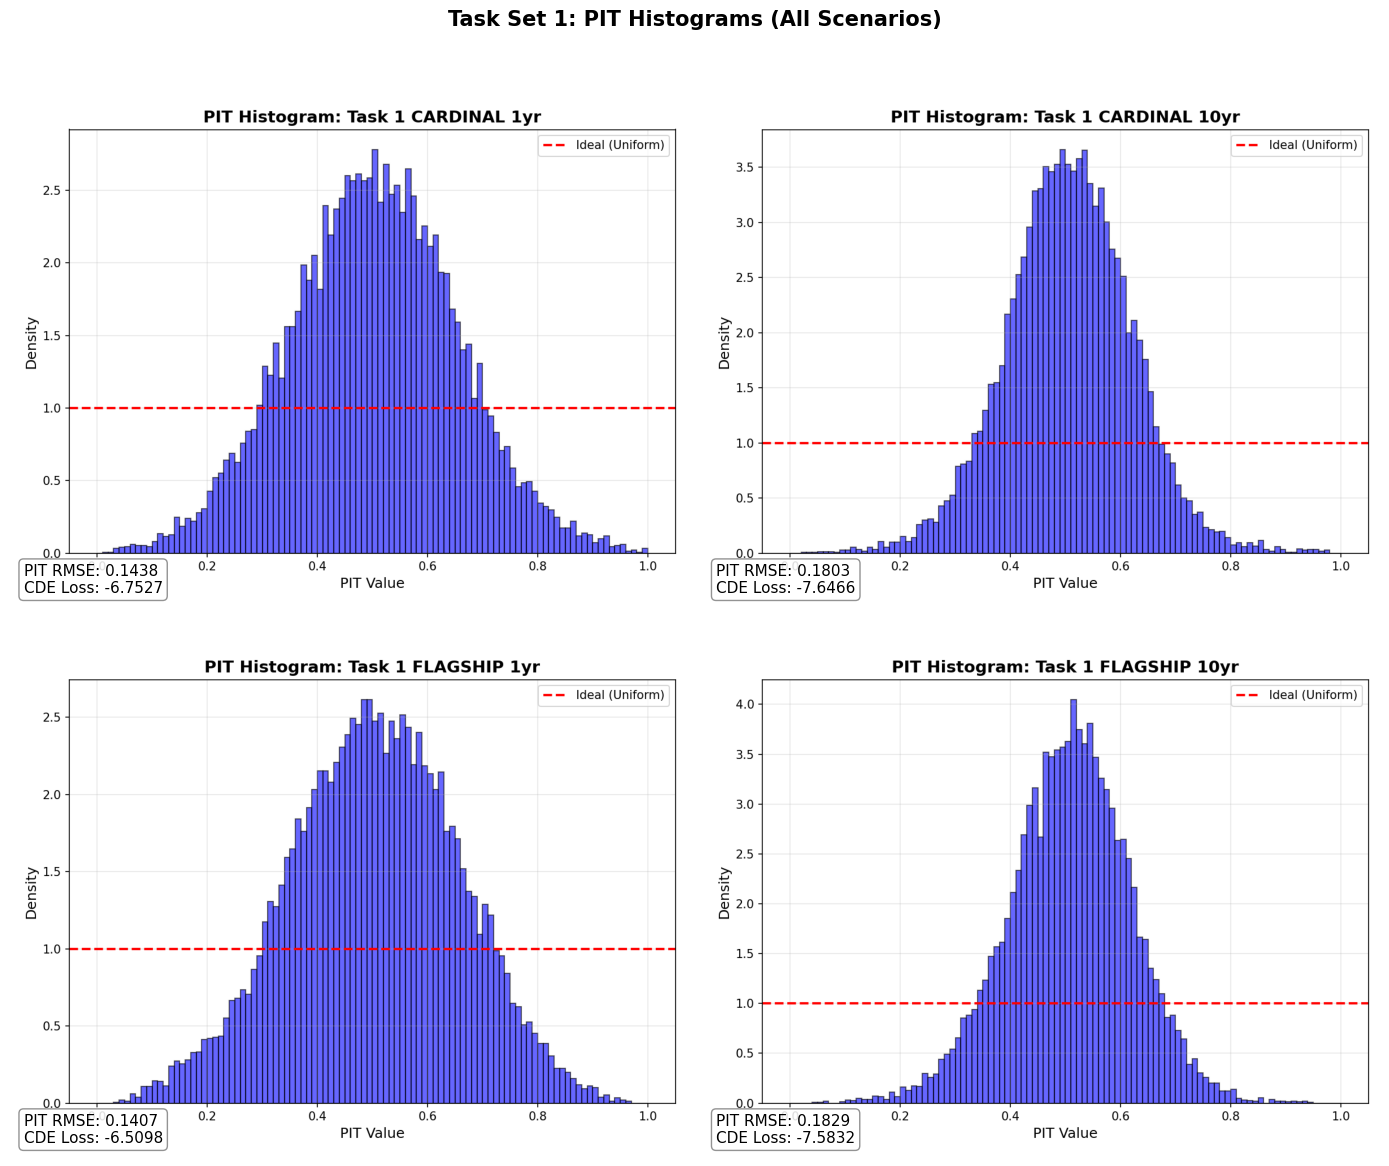

✅ Combined PIT histogram grid saved to: /content/outputs/taskset1_pit_histograms_combined.png


In [ ]:
#Cell 4

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

OUTPUT_PATH = Path('/content/outputs')

scenarios = [
    ('cardinal', '1yr'),
    ('cardinal', '10yr'),
    ('flagship', '1yr'),
    ('flagship', '10yr'),
]

# Build a lookup from the results list (from the main calculation cell)
# so we can annotate each subplot with its actual PIT RMSE / CDE Loss
metrics_lookup = {(r['sim'], r['scenario']): r for r in results}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Task Set 1: PIT Histograms (All Scenarios)',
              fontsize=15, fontweight='bold', y=1.0)

for ax, (sim, scenario) in zip(axes.flat, scenarios):
    img_path = OUTPUT_PATH / f'pit_hist_taskset_1_{sim}_{scenario}.png'
    if img_path.exists():
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.axis('off')

        key = (sim, scenario)
        if key in metrics_lookup:
            r = metrics_lookup[key]
            annotation = f"PIT RMSE: {r['pit_rmse']:.4f}\nCDE Loss: {r['cde_loss']:.4f}"
            ax.text(0.02, 0.02, annotation, transform=ax.transAxes,
                    fontsize=11, va='bottom', ha='left',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='gray'))
    else:
        ax.text(0.5, 0.5, f'Missing:\n{img_path.name}', ha='center', va='center')
        ax.axis('off')

plt.tight_layout()
save_path = OUTPUT_PATH / 'taskset1_pit_histograms_combined.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Combined PIT histogram grid saved to: {save_path}")

## Chart 1: Performance vs. LSST Requirements

- Plots the three LSST point-estimate requirements: bias < 0.003, sigma_RMSE < 0.02, outlier fraction < 10%
- One panel per metric, all four scenarios (Cardinal/Flagship × 1yr/10yr) shown side-by-side
- Red dashed line marks the requirement threshold in each panel
- Color indicates survey depth only (red = 1yr, green = 10yr), not pass/fail
- **Note:** these thresholds were applied to both 1yr and 10yr scenario

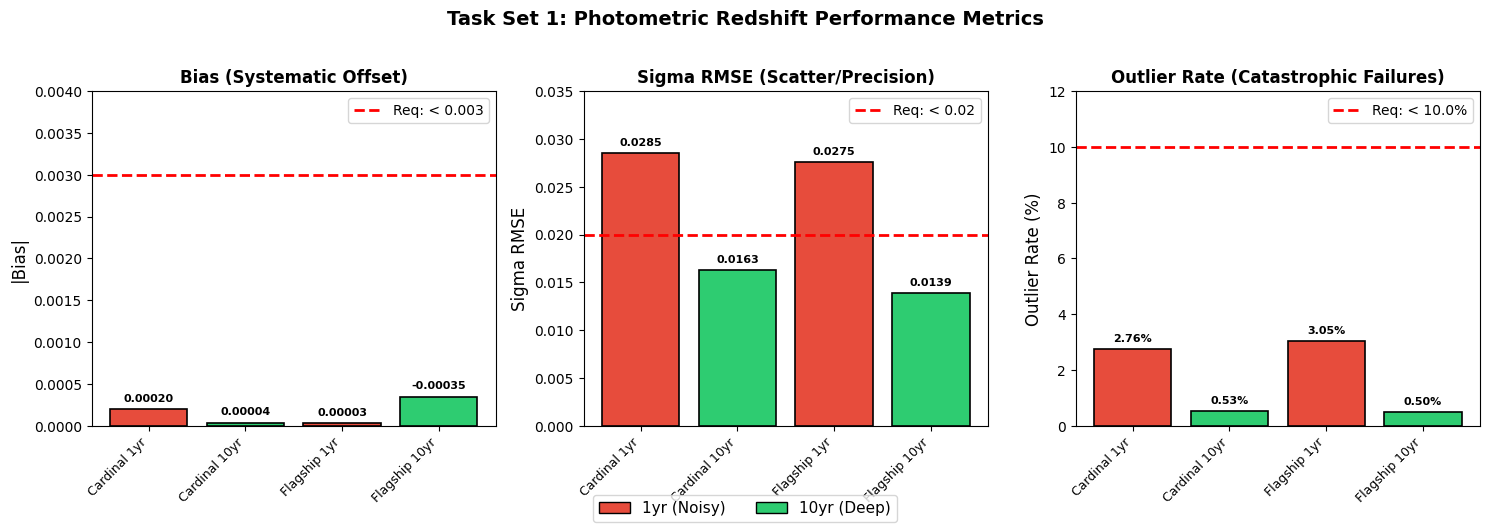

✅ Chart saved to: /content/outputs/taskset1_metrics.png


In [ ]:
#Cell 5
import matplotlib.pyplot as plt
import numpy as np
import os

# results
scenarios = ['Cardinal 1yr', 'Cardinal 10yr', 'Flagship 1yr', 'Flagship 10yr']
bias = [0.00020, 0.00004, 0.00003, -0.00035]
sigma_rmse = [0.02851, 0.01626, 0.02754, 0.01389]
outlier_rate = [2.76, 0.53, 3.05, 0.50]

# Corrected LSST requirements (point-estimate)
REQ_BIAS = 0.003
REQ_SIGMA_RMSE = 0.02
REQ_OUTLIER = 10.0

colors = ['#e74c3c', '#2ecc71', '#e74c3c', '#2ecc71']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Task Set 1: Photometric Redshift Performance Metrics',
             fontsize=14, fontweight='bold', y=1.02)

x = np.arange(len(scenarios))

# Panel 1: Bias
ax1 = axes[0]
bars1 = ax1.bar(x, np.abs(bias), color=colors, edgecolor='black', linewidth=1.2)
ax1.axhline(y=REQ_BIAS, color='red', linestyle='--', linewidth=2,
            label=f'Req: < {REQ_BIAS}')
ax1.set_ylabel('|Bias|', fontsize=12)
ax1.set_title('Bias (Systematic Offset)', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios, rotation=45, ha='right', fontsize=9)
ax1.legend(loc='upper right')
ax1.set_ylim(0, 0.004)
for bar, val in zip(bars1, bias):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.00007,
             f'{val:.5f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

# Panel 2: Sigma RMSE
ax2 = axes[1]
bars2 = ax2.bar(x, sigma_rmse, color=colors, edgecolor='black', linewidth=1.2)
ax2.axhline(y=REQ_SIGMA_RMSE, color='red', linestyle='--', linewidth=2,
            label=f'Req: < {REQ_SIGMA_RMSE}')
ax2.set_ylabel('Sigma RMSE', fontsize=12)
ax2.set_title('Sigma RMSE (Scatter/Precision)', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(scenarios, rotation=45, ha='right', fontsize=9)
ax2.legend(loc='upper right')
ax2.set_ylim(0, 0.035)
for bar, val in zip(bars2, sigma_rmse):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0006,
             f'{val:.4f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

# Panel 3: Outlier Rate
ax3 = axes[2]
bars3 = ax3.bar(x, outlier_rate, color=colors, edgecolor='black', linewidth=1.2)
ax3.axhline(y=REQ_OUTLIER, color='red', linestyle='--', linewidth=2,
            label=f'Req: < {REQ_OUTLIER}%')
ax3.set_ylabel('Outlier Rate (%)', fontsize=12)
ax3.set_title('Outlier Rate (Catastrophic Failures)', fontsize=12, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(scenarios, rotation=45, ha='right', fontsize=9)
ax3.legend(loc='upper right')
ax3.set_ylim(0, 12)
for bar, val in zip(bars3, outlier_rate):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{val:.2f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', edgecolor='black', label='1yr (Noisy)'),
                   Patch(facecolor='#2ecc71', edgecolor='black', label='10yr (Deep)')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=11,
           bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()

save_dir = '/content/outputs'
os.makedirs(save_dir, exist_ok=True)
save_path = f'{save_dir}/taskset1_metrics.png'

plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved to: {save_path}")

## Chart 2: 1-Year vs. 10-Year Survey Depth Comparison

- Direct side-by-side comparison of 1yr vs 10yr results, grouped by simulation (Cardinal, Flagship)
- Left panel: Sigma RMSE; right panel: outlier rate
- Same requirement thresholds shown as reference lines
- Purpose: isolate the effect of survey depth alone, holding simulation fixed

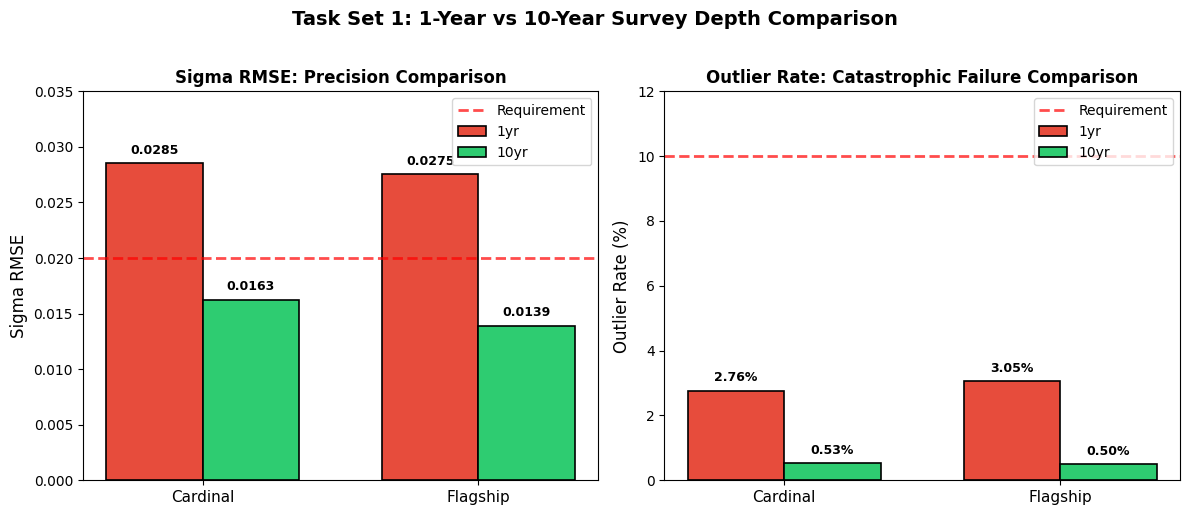

✅ Chart 2 saved to: /content/outputs/taskset1_comparison.png


In [ ]:
#Cell 6
import matplotlib.pyplot as plt
import numpy as np
import os

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Task Set 1: 1-Year vs 10-Year Survey Depth Comparison',
             fontsize=14, fontweight='bold', y=1.02)

x = np.arange(2)  # Cardinal, Flagship
width = 0.35

# Sigma RMSE comparison
ax1 = axes[0]
bars1 = ax1.bar(x - width/2, [0.02851, 0.02754], width, label='1yr',
                color='#e74c3c', edgecolor='black', linewidth=1.2)
bars2 = ax1.bar(x + width/2, [0.01626, 0.01389], width, label='10yr',
                color='#2ecc71', edgecolor='black', linewidth=1.2)
ax1.axhline(y=0.02, color='red', linestyle='--', linewidth=2, alpha=0.7,
            label='Requirement')
ax1.set_ylabel('Sigma RMSE', fontsize=12)
ax1.set_title('Sigma RMSE: Precision Comparison', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(['Cardinal', 'Flagship'], fontsize=11)
ax1.legend(loc='upper right')
ax1.set_ylim(0, 0.035)

for bar in list(bars1) + list(bars2):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0006,
             f'{bar.get_height():.4f}', ha='center', va='bottom',
             fontsize=9, fontweight='bold')

# Outlier comparison
ax2 = axes[1]
bars3 = ax2.bar(x - width/2, [2.76, 3.05], width, label='1yr',
                color='#e74c3c', edgecolor='black', linewidth=1.2)
bars4 = ax2.bar(x + width/2, [0.53, 0.50], width, label='10yr',
                color='#2ecc71', edgecolor='black', linewidth=1.2)
ax2.axhline(y=10.0, color='red', linestyle='--', linewidth=2, alpha=0.7,
            label='Requirement')
ax2.set_ylabel('Outlier Rate (%)', fontsize=12)
ax2.set_title('Outlier Rate: Catastrophic Failure Comparison',
              fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(['Cardinal', 'Flagship'], fontsize=11)
ax2.legend(loc='upper right')
ax2.set_ylim(0, 12)

for bar in list(bars3) + list(bars4):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{bar.get_height():.2f}%', ha='center', va='bottom',
             fontsize=9, fontweight='bold')

plt.tight_layout()

save_dir = '/content/outputs'
os.makedirs(save_dir, exist_ok=True)
save_path = f'{save_dir}/taskset1_comparison.png'

plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Chart 2 saved to: {save_path}")